<a href="https://colab.research.google.com/github/AbdullahRFA/IMDB_Sentiment_Analysis/blob/main/Module18_IMDB_Sentiment_Analysis_Abdullah_Nazmus_Sakib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis on Product Reviews (IMDB) || Customer Segmentation Analysis

**Project Description**

- In this assignment, you will work on sentiment analysis using the IMDB movie reviews dataset. The dataset contains 50,000 reviews equally divided into positive and negative sentiments. Your task is to build models that can classify whether a given review expresses a positive or negative opinion.
The focus of this project is on understanding how different text representation methods affect classification performance.
---



## import libraries and set random seeds

In [1]:

!pip install -q datasets pandas numpy


In [2]:

import random
import numpy as np
import pandas as pd

from datasets import load_dataset

# Set random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")
print("Random seed:", SEED)


Libraries imported successfully!
Random seed: 42


## Load the IMDB dataset

In [7]:
imdb = load_dataset("stanfordnlp/imdb")

print(imdb)


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


## Create training, validation, and test sets

In [8]:

# Split original training data into train and validation
train_valid = imdb["train"].train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="label"
)

train_ds = train_valid["train"]
val_ds = train_valid["test"]
test_ds = imdb["test"]

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Testing samples:", len(test_ds))


Training samples: 22500
Validation samples: 2500
Testing samples: 25000


In [9]:

# Display first five training reviews
for i in range(5):
    print(f"\nReview {i + 1}")
    print("Text:", train_ds[i]["text"][:500])
    print("Label:", train_ds[i]["label"])



Review 1
Text: Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link the prophecies as well as it can to what was happening in the times it was made, making it obviously dated and kind of silly.<br /><br />The reenactments look like they are out of "Unsolved Mysteries" b
Label: 0

Review 2
Text: This movie has one of the cheesiest plots I have seen. For me, that's what makes it so awesome! Fred Gwynne and Al Lewis are very good at what they achieved in the original Munsters series. While there was less slapstick, they still worked wonderfully together "comedically." I wish Yvonne De Carlo, as Lily, would have had more plot involvement. She showed that she could do comedy in the original series, but it was mostly wasted in this movie. This movie 

In [11]:

# Count positive and negative reviews
label_counts = pd.Series(
    train_ds["label"]
).value_counts().sort_index()

label_counts.index = ["Negative", "Positive"]

print(label_counts)


Negative    11250
Positive    11250
Name: count, dtype: int64


## Text Preprocessing

In [12]:

import re
import html

# Basic text cleaning function
def clean_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Test the function
sample_review = "<br /> THIS movie was AMAZING!!! I really loved it."

print("Original Review:")
print(sample_review)

print("\nCleaned Review:")
print(clean_text(sample_review))


Original Review:
<br /> THIS movie was AMAZING!!! I really loved it.

Cleaned Review:
this movie was amazing i really loved it


## Extract reviews and labels

In [13]:

# Extract original reviews
X_train_raw = train_ds["text"]
X_val_raw = val_ds["text"]
X_test_raw = test_ds["text"]

# Extract sentiment labels
y_train = np.array(train_ds["label"])
y_val = np.array(val_ds["label"])
y_test = np.array(test_ds["label"])

print("Training reviews:", len(X_train_raw))
print("Validation reviews:", len(X_val_raw))
print("Testing reviews:", len(X_test_raw))


Training reviews: 22500
Validation reviews: 2500
Testing reviews: 25000


## Apply basic cleaning for TF-IDF and Word2Vec

In [14]:

# Clean training, validation, and testing reviews

X_train_clean = [clean_text(review) for review in X_train_raw]

X_val_clean = [clean_text(review) for review in X_val_raw]

X_test_clean = [clean_text(review) for review in X_test_raw]

print("Preprocessing completed!")

print("\nOriginal review:")
print(X_train_raw[0][:300])

print("\nCleaned review:")
print(X_train_clean[0][:300])


Preprocessing completed!

Original review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th

Cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this train wreck this is a documentary about the biblical prophecies of armageddon it tries to link the pro


## Tokenization for Word2Vec

In [15]:

# Tokenize reviews for Word2Vec

X_train_tokens = [review.split() for review in X_train_clean]

X_val_tokens = [review.split() for review in X_val_clean]

X_test_tokens = [review.split() for review in X_test_clean]

# Display an example
print("Cleaned review:")
print(X_train_clean[0][:200])

print("\nTokenized review:")
print(X_train_tokens[0][:20])


Cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this tr

Tokenized review:
['every', 'generation', 'fully', 'believes', 'it', 'is', 'living', 'in', 'the', 'end', 'times', 'this', 'has', 'been', 'true', 'for', 'thousands', 'of', 'years', 'now']


## Prepare text for BERT
we'll preserve punctuation and capitalization.

In [16]:

def clean_text_for_bert(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Prepare BERT input text
X_train_bert = [
    clean_text_for_bert(review) for review in X_train_raw
]

X_val_bert = [
    clean_text_for_bert(review) for review in X_val_raw
]

X_test_bert = [
    clean_text_for_bert(review) for review in X_test_raw
]

print("Original review:")
print(X_train_raw[0][:300])

print("\nBERT-ready review:")
print(X_train_bert[0][:300])


Original review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th

BERT-ready review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th


## Verify preprocessing

In [17]:

# Verify dataset sizes
print("TF-IDF / Word2Vec")
print("Train:", len(X_train_clean))
print("Validation:", len(X_val_clean))
print("Test:", len(X_test_clean))

print("\nBERT")
print("Train:", len(X_train_bert))
print("Validation:", len(X_val_bert))
print("Test:", len(X_test_bert))

# Check for empty reviews
print("\nEmpty cleaned reviews:")
print("Train:", sum(not x for x in X_train_clean))
print("Validation:", sum(not x for x in X_val_clean))
print("Test:", sum(not x for x in X_test_clean))

# Check sentiment labels
print("\nTraining label distribution:")
print(pd.Series(y_train).value_counts().sort_index())


TF-IDF / Word2Vec
Train: 22500
Validation: 2500
Test: 25000

BERT
Train: 22500
Validation: 2500
Test: 25000

Empty cleaned reviews:
Train: 0
Validation: 0
Test: 0

Training label distribution:
0    11250
1    11250
Name: count, dtype: int64


## TF-IDF Vectorization and Sentiment Classification

In [18]:

# Import required libraries

import time
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TF-IDF libraries imported successfully!")


TF-IDF libraries imported successfully!


In [19]:

# Initialize TF-IDF vectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary and transform training reviews
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_clean)

# Transform validation and test reviews
X_val_tfidf = tfidf_vectorizer.transform(X_val_clean)

X_test_tfidf = tfidf_vectorizer.transform(X_test_clean)

print("TF-IDF vectorization completed!")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_val_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf_vectorizer.vocabulary_))


TF-IDF vectorization completed!

Training matrix shape: (22500, 50000)
Validation matrix shape: (2500, 50000)
Testing matrix shape: (25000, 50000)

Vocabulary size: 50000


In [20]:

# Inspect the first training review

print("Original cleaned review:")
print(X_train_clean[0][:300])

print("\nTF-IDF vector shape:")
print(X_train_tfidf[0].shape)

print("\nNon-zero TF-IDF features:")
print(X_train_tfidf[0].nnz)

# Display the first 15 non-zero features
feature_names = tfidf_vectorizer.get_feature_names_out()

row = X_train_tfidf[0]

nonzero_indices = row.indices[:15]
nonzero_values = row.data[:15]

for index, value in zip(nonzero_indices, nonzero_values):
    print(f"{feature_names[index]}: {value:.4f}")


Original cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this train wreck this is a documentary about the biblical prophecies of armageddon it tries to link the pro

TF-IDF vector shape:
(1, 50000)

Non-zero TF-IDF features:
166
every: 0.0461
generation: 0.0873
fully: 0.0781
believes: 0.0880
it: 0.0444
is: 0.0355
living: 0.0652
in: 0.0410
the: 0.0473
end: 0.0413
times: 0.0822
this: 0.0468
has: 0.0291
been: 0.0600
true: 0.0538


## Train the Logistic Regression classifier

In [21]:

# Initialize Logistic Regression

tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

# Measure training time
start_time = time.time()

# Train the model
tfidf_model.fit(X_train_tfidf, y_train)

tfidf_training_time = time.time() - start_time

print("TF-IDF model training completed!")
print(f"Training time: {tfidf_training_time:.2f} seconds")


TF-IDF model training completed!
Training time: 4.55 seconds


## Make predictions on validation data

In [22]:

# Predict sentiment using validation data

start_time = time.time()

y_val_pred_tfidf = tfidf_model.predict(X_val_tfidf)

tfidf_prediction_time = time.time() - start_time

print("Validation predictions completed!")

print("\nActual labels:")
print(y_val[:10])

print("\nPredicted labels:")
print(y_val_pred_tfidf[:10])


Validation predictions completed!

Actual labels:
[0 1 0 0 1 1 0 1 0 0]

Predicted labels:
[0 1 1 0 1 1 0 1 0 1]


## Evaluate model performance

In [23]:

# Calculate evaluation metrics

tfidf_accuracy = accuracy_score(
    y_val, y_val_pred_tfidf
)

tfidf_precision = precision_score(
    y_val, y_val_pred_tfidf
)

tfidf_recall = recall_score(
    y_val, y_val_pred_tfidf
)

tfidf_f1 = f1_score(
    y_val, y_val_pred_tfidf
)

# Display results
print("TF-IDF + Logistic Regression Results")
print("------------------------------------")

print(f"Accuracy:  {tfidf_accuracy:.4f}")
print(f"Precision: {tfidf_precision:.4f}")
print(f"Recall:    {tfidf_recall:.4f}")
print(f"F1-score:  {tfidf_f1:.4f}")

print(f"Training time: {tfidf_training_time:.2f} seconds")
print(f"Prediction time: {tfidf_prediction_time:.2f} seconds")


TF-IDF + Logistic Regression Results
------------------------------------
Accuracy:  0.8992
Precision: 0.8960
Recall:    0.9032
F1-score:  0.8996
Training time: 4.55 seconds
Prediction time: 0.01 seconds


## Generate a classification report

In [24]:

print(
    classification_report(
        y_val,
        y_val_pred_tfidf,
        target_names=["Negative", "Positive"]
    )
)


              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90      1250
    Positive       0.90      0.90      0.90      1250

    accuracy                           0.90      2500
   macro avg       0.90      0.90      0.90      2500
weighted avg       0.90      0.90      0.90      2500



## confusion matrix

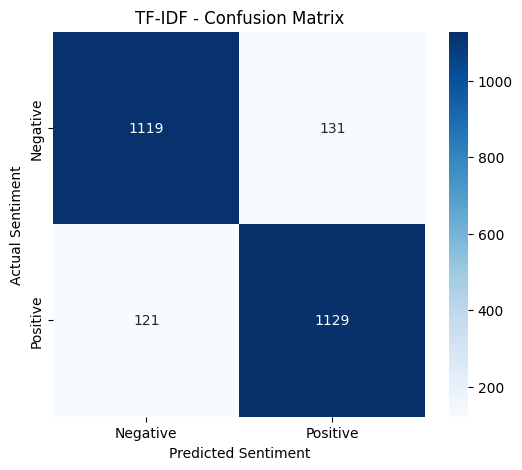

In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred_tfidf
)

# Visualize confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("TF-IDF - Confusion Matrix")

plt.show()


In [26]:

# Custom movie reviews

custom_reviews = [
    "This movie was absolutely amazing. I loved every moment.",
    "The film was terrible and extremely boring.",
    "The acting was excellent and the story was wonderful.",
    "I wasted my time watching this awful movie."
]

# Apply the same cleaning process
custom_reviews_clean = [
    clean_text(review) for review in custom_reviews
]

# Convert reviews into TF-IDF features
custom_reviews_tfidf = tfidf_vectorizer.transform(
    custom_reviews_clean
)

# Predict sentiments
custom_predictions = tfidf_model.predict(
    custom_reviews_tfidf
)

# Display predictions
for review, prediction in zip(
    custom_reviews, custom_predictions
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 60)


Review: This movie was absolutely amazing. I loved every moment.
Predicted sentiment: Positive
------------------------------------------------------------
Review: The film was terrible and extremely boring.
Predicted sentiment: Negative
------------------------------------------------------------
Review: The acting was excellent and the story was wonderful.
Predicted sentiment: Positive
------------------------------------------------------------
Review: I wasted my time watching this awful movie.
Predicted sentiment: Negative
------------------------------------------------------------


## Save TF-IDF results for our final comparison

In [27]:

# Store TF-IDF validation results

tfidf_results = {
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": tfidf_accuracy,
    "Precision": tfidf_precision,
    "Recall": tfidf_recall,
    "F1-Score": tfidf_f1,
    "Training Time (seconds)": tfidf_training_time,
    "Prediction Time (seconds)": tfidf_prediction_time
}

print(pd.DataFrame([tfidf_results]).round(4))


                          Model  Accuracy  Precision  Recall  F1-Score  \
0  TF-IDF + Logistic Regression    0.8992      0.896  0.9032    0.8996   

   Training Time (seconds)  Prediction Time (seconds)  
0                   4.5531                      0.007  
